# Datenexploration

## Init

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
file_path = '../../data/raw/sickness_table.csv'

df = pd.read_csv(file_path, index_col=0)

# Explorative Datenanalyse (EDA)

In [2]:
# Convert date column to datetime
df['date'] = pd.to_datetime(df['date'])

# Dateninspektion
display(df.info())
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
Index: 1152 entries, 0 to 1151
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   date      1152 non-null   datetime64[ns]
 1   n_sick    1152 non-null   int64         
 2   calls     1152 non-null   float64       
 3   n_duty    1152 non-null   int64         
 4   n_sby     1152 non-null   int64         
 5   sby_need  1152 non-null   float64       
 6   dafted    1152 non-null   float64       
dtypes: datetime64[ns](1), float64(3), int64(3)
memory usage: 72.0 KB


None

,date,n_sick,calls,n_duty,n_sby,sby_need,dafted
count,1152,1152.000000,1152.000000,1152.000000,1152.0,1152.000000,1152.000000
mean,2017-10-28 12:00:00,68.808160,7919.531250,1820.572917,90.0,34.718750,16.335938
min,2016-04-01 00:00:00,36.000000,4074.000000,1700.000000,90.0,0.000000,0.000000
25%,2017-01-13 18:00:00,58.000000,6978.000000,1800.000000,90.0,0.000000,0.000000
50%,2017-10-28 12:00:00,68.000000,7932.000000,1800.000000,90.0,0.000000,0.000000
75%,2018-08-12 06:00:00,78.000000,8827.500000,1900.000000,90.0,12.250000,0.000000
max,2019-05-27 00:00:00,119.000000,11850.000000,1900.000000,90.0,555.000000,465.000000
std,NaN,14.293942,1290.063571,80.086953,0.0,79.694251,53.394089


In [3]:
display(df)

,date,n_sick,calls,n_duty,n_sby,sby_need,dafted
0,2016-04-01,73,8154.0,1700,90,4.0,0.0
1,2016-04-02,64,8526.0,1700,90,70.0,0.0
2,2016-04-03,68,8088.0,1700,90,0.0,0.0
3,2016-04-04,71,7044.0,1700,90,0.0,0.0
4,2016-04-05,63,7236.0,1700,90,0.0,0.0
...,...,...,...,...,...,...,...
1147,2019-05-23,86,8544.0,1900,90,0.0,0.0
1148,2019-05-24,81,8814.0,1900,90,0.0,0.0
1149,2019-05-25,76,9846.0,1900,90,146.0,56.0
1150,2019-05-26,83,9882.0,1900,90,160.0,70.0


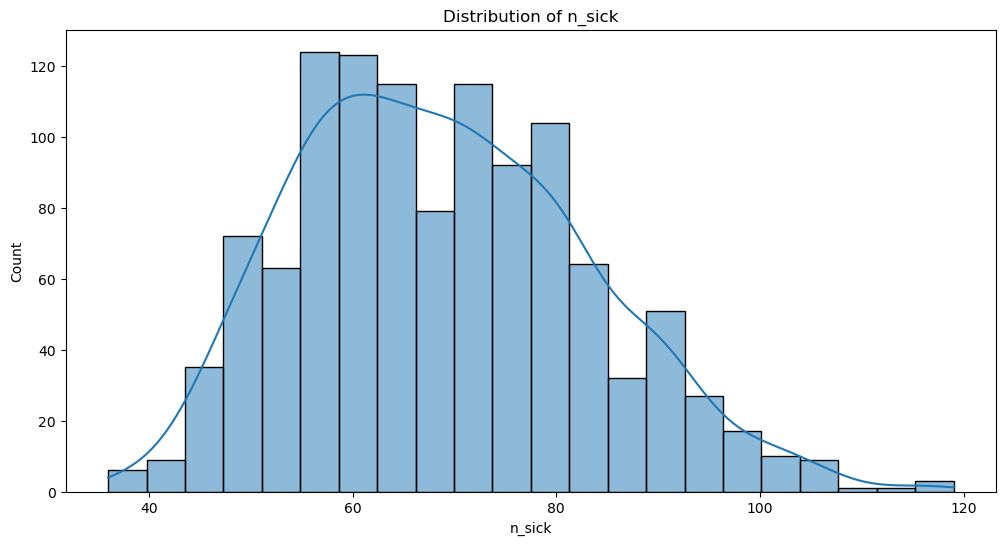

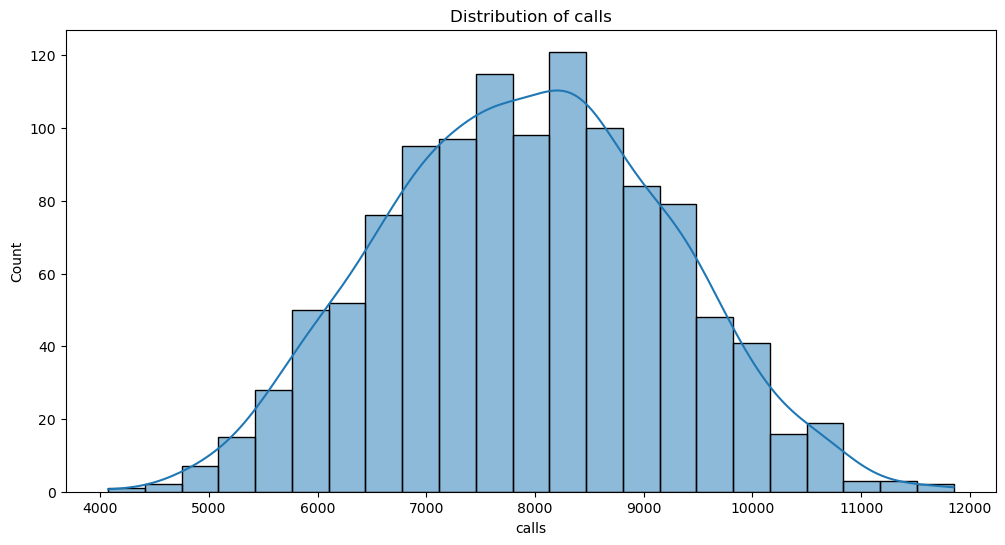

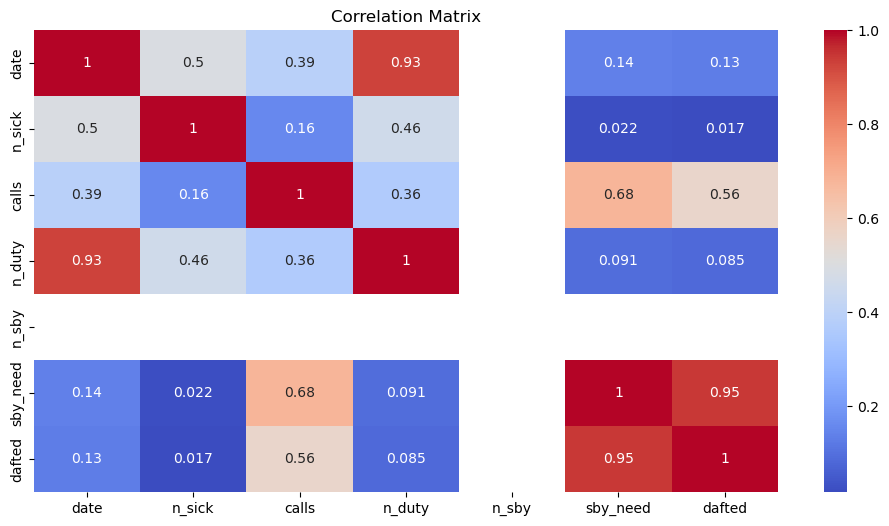

In [4]:
# Visualisierungen
plt.figure(figsize=(12, 6))
sns.histplot(df['n_sick'], kde=True)
plt.title('Distribution of n_sick')
plt.show()

plt.figure(figsize=(12, 6))
sns.histplot(df['calls'], kde=True)
plt.title('Distribution of calls')
plt.show()

plt.figure(figsize=(12, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

#To-Do: Visualiserung und Verteilung der Anrufe ist evtl. nicht ideal

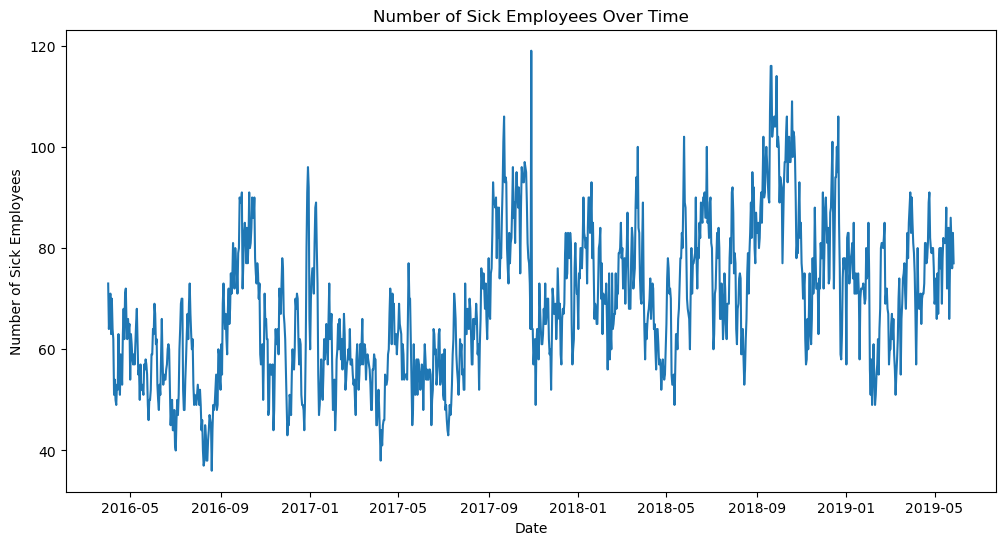

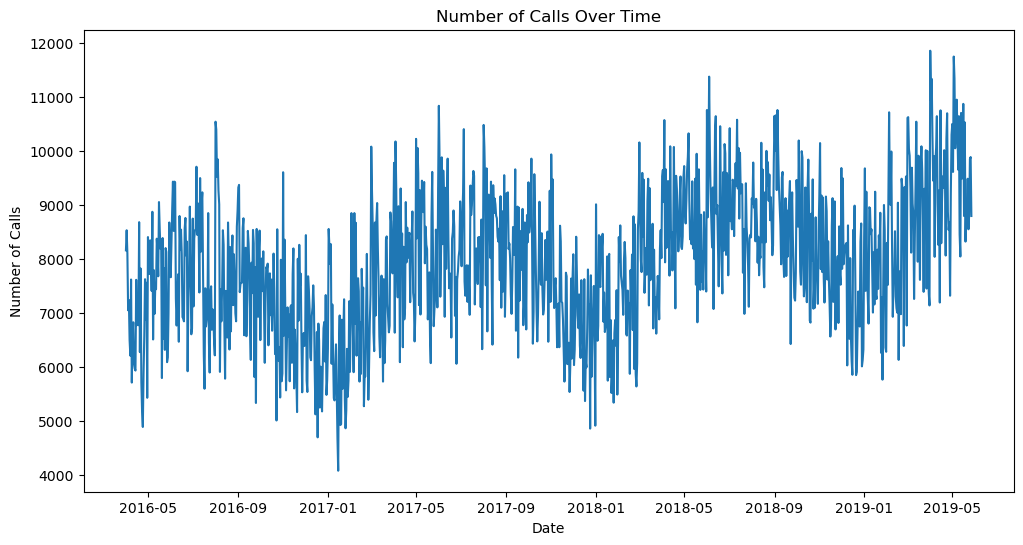

In [5]:
# Plot n_sick over time
plt.figure(figsize=(12, 6))
sns.lineplot(data=df, x='date', y='n_sick')
plt.title('Number of Sick Employees Over Time')
plt.xlabel('Date')
plt.ylabel('Number of Sick Employees')
plt.show()

# Plot calls over time
plt.figure(figsize=(12, 6))
sns.lineplot(data=df, x='date', y='calls')
plt.title('Number of Calls Over Time')
plt.xlabel('Date')
plt.ylabel('Number of Calls')
plt.show()


# Datenvorbereitung

In [6]:
working_df = df.copy(deep=True)

print("Number NaN values:", working_df.isna().sum())

# Umgang mit fehlenden Werten
working_df = working_df.dropna()

Number NaN values: date        0
n_sick      0
calls       0
n_duty      0
n_sby       0
sby_need    0
dafted      0
dtype: int64


In [7]:
# Feature Engineering
working_df['month'] = working_df['date'].dt.month
working_df['day_of_week'] = working_df['date'].dt.dayofweek

working_df["calls_per_duty"] = working_df.apply(lambda row: row.calls / row.n_duty, axis=1)
working_df["call_stress"] = working_df.apply(lambda row: row.calls / (row.n_duty + row.sby_need), axis=1)
working_df["sby_used_percent"] = working_df.apply(lambda row: (row.sby_need / row.n_sby) * 100, axis=1)
# Ziel: Prediction wo sby_used_percent nahe 100% ist, aber nicht drüber. Sprich dafted ist noch 0


print("New dataframe:")
display(working_df)
display(working_df.describe())

New dataframe:


,date,n_sick,calls,n_duty,n_sby,sby_need,dafted,month,day_of_week,calls_per_duty,call_stress,sby_used_percent
0,2016-04-01,73,8154.0,1700,90,4.0,0.0,4,4,4.796471,4.785211,4.444444
1,2016-04-02,64,8526.0,1700,90,70.0,0.0,4,5,5.015294,4.816949,77.777778
2,2016-04-03,68,8088.0,1700,90,0.0,0.0,4,6,4.757647,4.757647,0.000000
3,2016-04-04,71,7044.0,1700,90,0.0,0.0,4,0,4.143529,4.143529,0.000000
4,2016-04-05,63,7236.0,1700,90,0.0,0.0,4,1,4.256471,4.256471,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...
1147,2019-05-23,86,8544.0,1900,90,0.0,0.0,5,3,4.496842,4.496842,0.000000
1148,2019-05-24,81,8814.0,1900,90,0.0,0.0,5,4,4.638947,4.638947,0.000000
1149,2019-05-25,76,9846.0,1900,90,146.0,56.0,5,5,5.182105,4.812317,162.222222
1150,2019-05-26,83,9882.0,1900,90,160.0,70.0,5,6,5.201053,4.797087,177.777778


,date,n_sick,calls,n_duty,n_sby,sby_need,dafted,month,day_of_week,calls_per_duty,call_stress,sby_used_percent
count,1152,1152.000000,1152.000000,1152.000000,1152.0,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000
mean,2017-10-28 12:00:00,68.808160,7919.531250,1820.572917,90.0,34.718750,16.335938,6.424479,3.002604,4.347109,4.255659,38.576389
min,2016-04-01 00:00:00,36.000000,4074.000000,1700.000000,90.0,0.000000,0.000000,1.000000,0.000000,2.263333,2.263333,0.000000
25%,2017-01-13 18:00:00,58.000000,6978.000000,1800.000000,90.0,0.000000,0.000000,4.000000,1.000000,3.875833,3.875833,0.000000
50%,2017-10-28 12:00:00,68.000000,7932.000000,1800.000000,90.0,0.000000,0.000000,6.000000,3.000000,4.344298,4.344298,0.000000
75%,2018-08-12 06:00:00,78.000000,8827.500000,1900.000000,90.0,12.250000,0.000000,9.000000,5.000000,4.831625,4.778991,13.611111
max,2019-05-27 00:00:00,119.000000,11850.000000,1900.000000,90.0,555.000000,465.000000,12.000000,6.000000,6.236842,4.896288,616.666667
std,NaN,14.293942,1290.063571,80.086953,0.0,79.694251,53.394089,3.394101,2.002386,0.663532,0.539535,88.549168


In [8]:
# Datenaufteilung
from sklearn.model_selection import train_test_split

X = working_df[['calls', 'n_duty', 'n_sby', 'n_sick', 'month', 'day_of_week', 'call_stress', 'calls_per_duty']] #dafted für Training weglassen, da dies direkt Aufschluss darüber gibt, dass der Wert über 100 liegt

# Annahme: n_sby soll vorhergesagt werden, aber da es in der Historie fest den Wert 90 hat, kann man darauf nicht direkt predicten
# Ziel: sby_used_percent soll nahezu 100% betragen, aber nicht darüber liegen. To-Do: n_sby ausrechnen. 
# Idee: Eingabe an API mit Werten rein. Programm sagt, Warnung, die Kapazitäten werden voraussichtlich nur zu X Prozent genutzt und entsprechend wird bei n_sby dann reduziert. Im Umkehrfall bei über 100% wird erhöht
y = working_df['sby_used_percent']  

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Baseline-Modell

Baseline MAE: 72.95070554571097


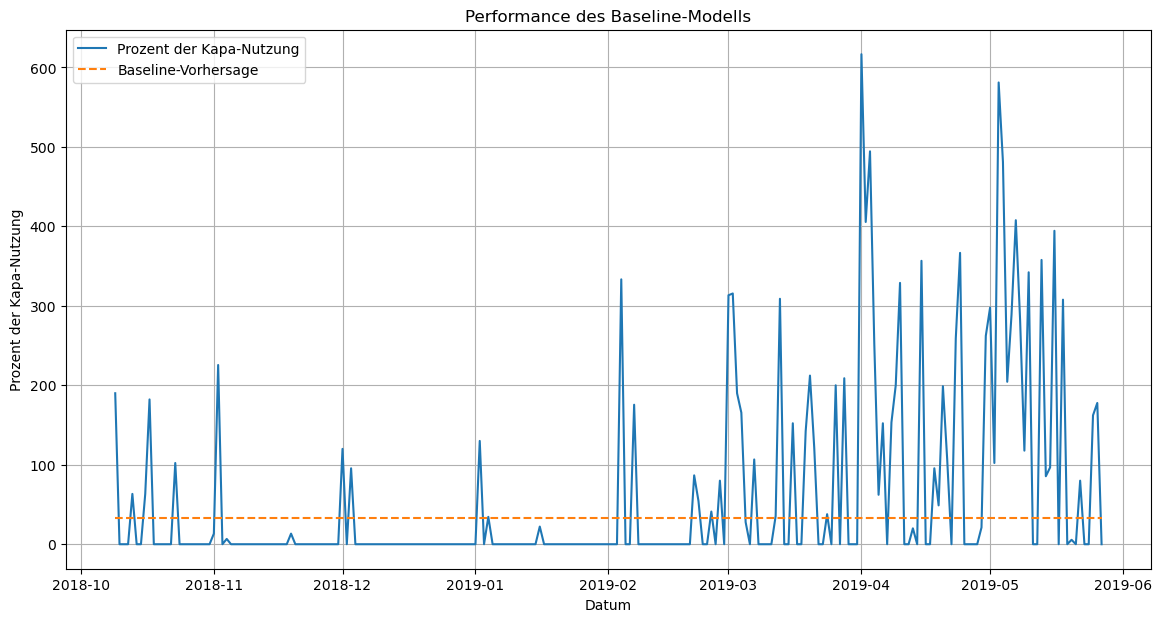

In [9]:
from sklearn.metrics import mean_absolute_error

train_size = int(len(working_df) * 0.8)
train, test = working_df.iloc[:train_size], working_df.iloc[train_size:]

# Baseline-Modell: Durchschnitt der Zielvariable im Trainingsset
mean_sick_train = train['sby_used_percent'].mean()

test = test.copy() # Zum Verhindern der SettingWithCopyWarning
# Vorhersagen für das Testset mit dem Baseline-Modell
test['baseline_pred'] = mean_sick_train

# Berechnung des Mean Absolute Error (MAE) für das Baseline-Modell
mae_baseline = mean_absolute_error(test['sby_used_percent'], test['baseline_pred'])
print(f'Baseline MAE: {mae_baseline}')

# Visualisierung der Performance des Baseline-Modells
plt.figure(figsize=(14, 7))
plt.plot(test['date'], test['sby_used_percent'], label='Prozent der Kapa-Nutzung')
plt.plot(test['date'], test['baseline_pred'], label='Baseline-Vorhersage', linestyle='--')
plt.xlabel('Datum')
plt.ylabel('Prozent der Kapa-Nutzung')
plt.title('Performance des Baseline-Modells')
plt.legend()
plt.grid(True)
plt.show()

## Erstellung und Evaluation des Vorhersagemodells

Model MAE: 1.5673400673400701
Best Model MAE: 1.5333596694863332

Feature importance:
n_sby: 0.0
n_duty: 0.00012628020138053835
day_of_week: 0.00039213091738546986
month: 0.00046014848362781825
call_stress: 0.0018899164564809949
n_sick: 0.002123120460281674
calls: 0.007239597652523824
calls_per_duty: 0.9877688058283197



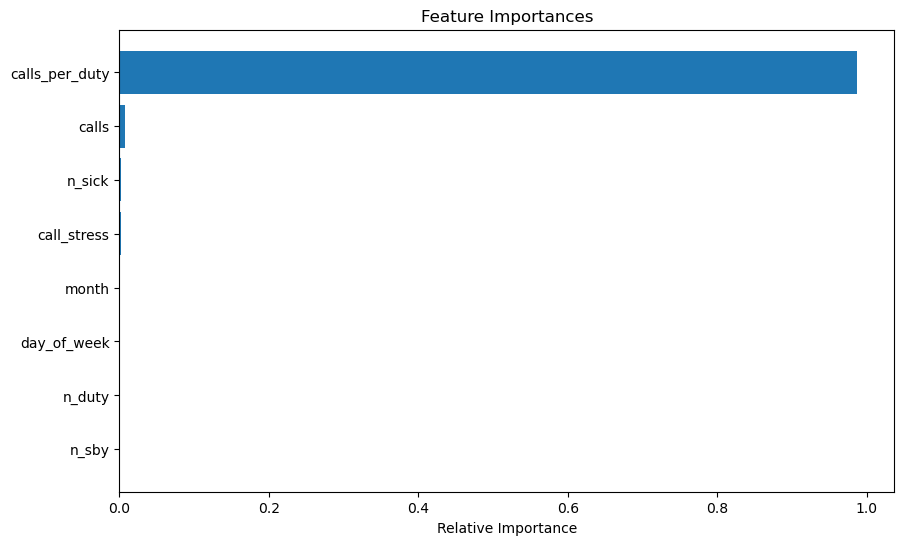

In [10]:
# Auswahl und Training eines Modells
from sklearn.ensemble import RandomForestRegressor

# Als einfacher Start. Bested Modell wird später rausgesucht
model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(f'Model MAE: {mean_absolute_error(y_test, y_pred)}')

# Hyperparameter-Tuning (optional)
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5]
}

grid_search = GridSearchCV(model, param_grid, cv=5, scoring='neg_mean_absolute_error')
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test)

print(f'Best Model MAE: {mean_absolute_error(y_test, y_pred_best)}')

# Visualisierung und Kommunikation der Ergebnisse

# Feature Importance
importances = best_model.feature_importances_
features = X.columns
indices = np.argsort(importances)

print("\nFeature importance:")
[print(features[i] + ":", importances[i]) for i in indices]
print("")

plt.figure(figsize=(10, 6))
plt.title('Feature Importances')
plt.barh(range(len(indices)), importances[indices], align='center')
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()

# Datenexport

In [11]:
working_df.to_csv("../../data/processed/sickness_table.csv")